# 01 — Independent SAM–Vicon synchronization (SAM + MediaPipe)

Compare **two independent video arm-raise signals** for each camera against the same Vicon reference. Both use original video-clock timestamps. Generate source-specific synchronization candidates and **select one explicitly per camera**. Do not use joint-angle curves to pick a lag or automatically approve synchronization.

Run from the repository root or `notebooks/`. Use SAM-only joint-angle CSVs containing original `time_ms` for downstream validation; legacy `time_ms_aligned` files need separate provenance-aware recovery.


In [38]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ezc3d
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir() and (ROOT.parent / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise FileNotFoundError('Run Jupyter from markerless_sam/ or notebooks/')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.synchronization import synchronize

# Single source of configuration — change these for another trial.
SUBJECT = 'S1'
TRIAL = 'lunge_01'
SYNC_ARM = 'right'  # same physical arm in SAM and Vicon

if SYNC_ARM not in ("left", "right"):
    raise ValueError("SYNC_ARM must be left or right")

SYNC_EVENT = 'arm_raise'
SYNC_SIGNAL = f'{SYNC_ARM}_arm_raise'

# S1 only: manually identify the same first knee bend in each recording.
# Enter original recording timestamps in milliseconds.
S1_VICON_EVENT_MS = None
S1_VIDEO_EVENT_MS = {'cam0': None, 'cam1': None}

CAMERAS = ('cam0', 'cam1') #leave out cam2 for now, as it is unreliable
WINDOW_MS = 8000.0  # searches from start of each recording; verify the same event
SYNC_SOURCES = ('sam', 'mediapipe')
# Explicit selection after visually reviewing BOTH source candidates.
# None means no selection; preserves existing sync_candidate.json.
SELECTED_SOURCE = {camera: None for camera in CAMERAS}

DATA_DIR = ROOT / 'lunge_sam_out'
RESULTS_DIR = ROOT / 'results'
TRIAL_DIR = DATA_DIR / SUBJECT / TRIAL

# Current C3D naming: S9/lunge_01 corresponds to s9_lunge_0_1.c3d.
C3D_PATH = TRIAL_DIR / f'{SUBJECT.lower()}_lunge_0_1.c3d'
if not C3D_PATH.is_file():
    C3D_PATH = DATA_DIR / f'{SUBJECT.lower()}_lunge_0_1.c3d'
VICON_SYNC_PATH = TRIAL_DIR / 'vicon_sync.csv'
print('Repository:', ROOT)
print('C3D:', C3D_PATH, 'exists:', C3D_PATH.is_file())
print('Trial directory:', TRIAL_DIR)


Repository: /Users/thomasjohnson/markerless/markerless_sam
C3D: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01/s1_lunge_0_1.c3d exists: True
Trial directory: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01


## 1. Export Vicon reference arm signals — once per trial

The Vicon wrist/hand displacement is projected onto trunk-up and normalized by torso length; it is a **sync proxy**, not an anatomical shoulder angle. Check actual marker names and C3D first-frame/time metadata. The same Vicon reference is reused across cameras.


In [39]:
if not C3D_PATH.is_file():
    candidates = sorted(DATA_DIR.rglob('*.c3d'))
    raise FileNotFoundError(f'{C3D_PATH} missing. Available: {[str(p.relative_to(DATA_DIR)) for p in candidates]}')

c3d = ezc3d.c3d(str(C3D_PATH))
labels = [str(label).strip() for label in c3d['parameters']['POINT']['LABELS']['value']]
points = c3d['data']['points']
fps = float(c3d['header']['points']['frame_rate'])
required = ('LCLAVLAT', 'RCLAVLAT', 'LHAND', 'RHAND', 'LASI', 'RASI')
missing = sorted(set(required) - set(labels))
if missing:
    raise KeyError(f'Missing markers {missing}; inspect labels: {labels}')

def marker(name):
    return np.asarray(points[:3, labels.index(name), :].T, dtype=float)

l_sh, r_sh = marker('LCLAVLAT'), marker('RCLAVLAT')
l_hand, r_hand = marker('LHAND'), marker('RHAND')
lasis, rasis = marker('LASI'), marker('RASI')
up_vector = (l_sh + r_sh - lasis - rasis) / 2.0
torso_length = np.linalg.norm(up_vector, axis=1)
valid_torso = np.isfinite(torso_length) & (torso_length > 1e-6)
up = np.full_like(up_vector, np.nan)
up[valid_torso] = up_vector[valid_torso] / torso_length[valid_torso, None]

def arm_raise(hand, shoulder):
    height = np.sum((hand - shoulder) * up, axis=1)
    return np.divide(height, torso_length, out=np.full_like(height, np.nan), where=valid_torso)

left_raise = arm_raise(l_hand, l_sh)
right_raise = arm_raise(r_hand, r_sh)

# Native sampling starts at the first stored frame. Check C3D first_frame
# and acquisition metadata if an external clock origin is needed.
vicon_sync = pd.DataFrame({
    'time_ms': np.arange(points.shape[2], dtype=float) * 1000.0 / fps,
    'left_arm_raise': left_raise,
    'right_arm_raise': right_raise,
})
VICON_SYNC_PATH.parent.mkdir(parents=True, exist_ok=True)
vicon_sync.to_csv(VICON_SYNC_PATH, index=False)
print('Saved:', VICON_SYNC_PATH, '| frames:', len(vicon_sync), '| rate:', fps)
display(vicon_sync.head())


Saved: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01/vicon_sync.csv | frames: 975 | rate: 100.0


,time_ms,left_arm_raise,right_arm_raise
0,0.0,-1.342888,-1.336970
1,10.0,-1.342950,-1.337023
2,20.0,-1.343014,-1.337082
3,30.0,-1.343080,-1.337146
4,40.0,-1.343148,-1.337215


## 2. Inspect both SAM and MediaPipe video synchronization inputs

Each source has its own **native samples**, recorded against the original video frame clock (`ts`, in ms). Never concatenate the two signals row-wise. For each camera, inspect both signals and ensure the intended *same physical arm raise* appears in the Vicon recording.


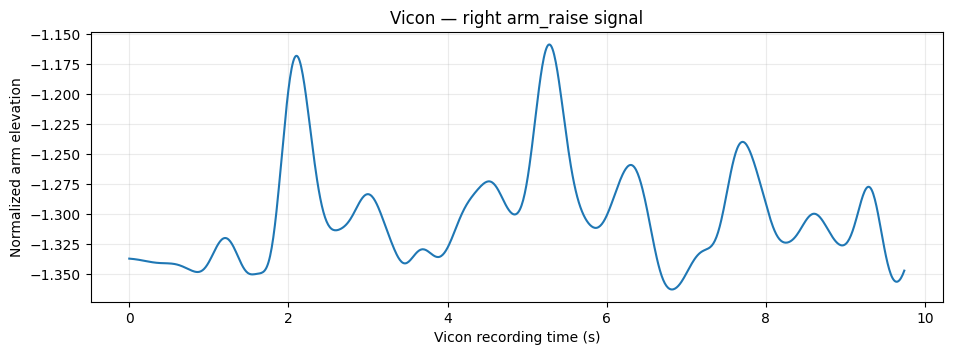

cam0 sam: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01/s1_lunge_cam0_sam_sync.csv — found
cam0 mediapipe: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01/s1_lunge_cam0_mediapipe_sync.csv — found


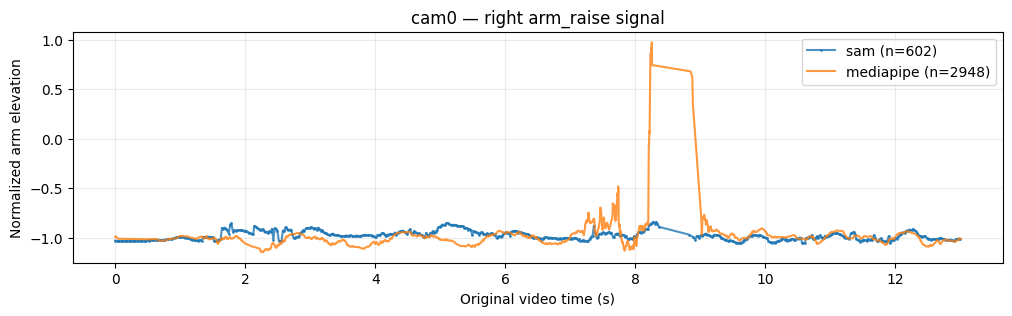

cam1 sam: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01/s1_lunge_cam1_sam_sync.csv — found
cam1 mediapipe: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01/s1_lunge_cam1_mediapipe_sync.csv — found


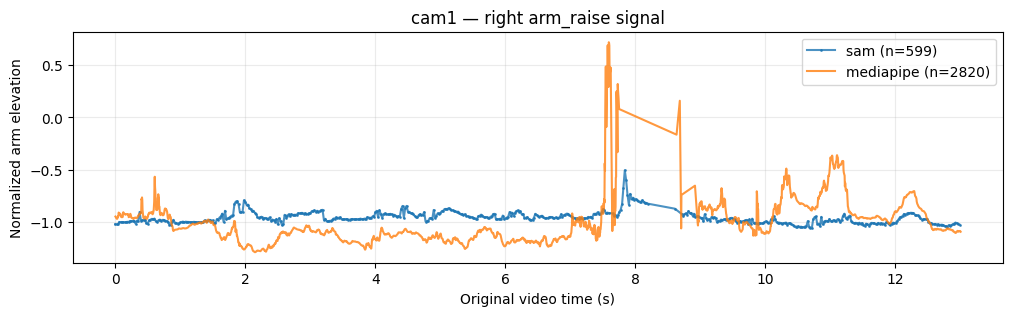

In [40]:

vicon_col = SYNC_SIGNAL
signal_label = 'Normalized arm elevation'

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(vicon_sync['time_ms']/1000, vicon_sync[vicon_col])
ax.set(xlabel='Vicon recording time (s)', ylabel=signal_label,
       title=f'Vicon — {SYNC_ARM} {SYNC_EVENT} signal')
ax.grid(alpha=.25)
plt.show()


def sync_path(camera, source):
    suffix = 'sam_sync.csv' if source == 'sam' else 'mediapipe_sync.csv'
    name = f'{SUBJECT.lower()}_lunge_{camera}_{suffix}'
    trial_path = TRIAL_DIR / name
    legacy_path = DATA_DIR / name
    return trial_path if trial_path.is_file() else legacy_path


SYNC_INPUTS = {
    camera: {source: sync_path(camera, source) for source in SYNC_SOURCES}
    for camera in CAMERAS
}

for camera, paths in SYNC_INPUTS.items():
    fig, ax = plt.subplots(figsize=(12, 3))
    found = False
    for source, path in paths.items():
        print(f'{camera} {source}: {path} — {"found" if path.is_file() else "MISSING"}')
        if not path.is_file():
            continue
        df = pd.read_csv(path)
        needed = {'ts', f'{SYNC_SIGNAL}'}
        if not needed.issubset(df):
            print(' Missing columns:', sorted(needed - set(df)))
            continue
        found = True
        ax.plot(df['ts']/1000, df[f'{SYNC_SIGNAL}'],
                marker='.' if source == 'sam' else None, ms=2,
                label=f'{source} (n={len(df)})', alpha=.8)
    if found:
        ax.set(xlabel='Original video time (s)', ylabel=signal_label,
               title=f'{camera} — {SYNC_ARM} {SYNC_EVENT} signal')
        ax.legend()
        ax.grid(alpha=.25)
        plt.show()
    else:
        plt.close(fig)


## 3. Generate separate synchronization candidates, then select explicitly

Each source writes `sync_candidate_sam.json/png` or `sync_candidate_mediapipe.json/png`, **without overwriting** the existing canonical `sync_candidate.json`. Compare both candidates and review the physical event. Set `SELECTED_SOURCE` in the configuration and rerun the final selection cell to write the chosen candidate to the canonical location. Selection retains `status='review'`; it does **not** constitute scientific approval.


In [41]:
import json
from dataclasses import asdict
from src.synchronization import SyncResult

records = []
generated_candidates = set()

for camera in CAMERAS:
    out_dir = RESULTS_DIR / SUBJECT / TRIAL / camera
    out_dir.mkdir(parents=True, exist_ok=True)

    for source, video_sync_path in SYNC_INPUTS[camera].items():
        row = dict(
            subject=SUBJECT, trial=TRIAL, camera=camera,
            source=source, arm=SYNC_ARM,
            video_sync_file=video_sync_path.name,
        )

        # S1 uses manually identified timestamps, so arm CSVs aren't required.
        if SUBJECT.upper() != 'S1' and not video_sync_path.is_file():
            records.append({**row, 'status': 'missing_video_sync'})
            continue

        try:
            if SUBJECT.upper() == 'S1':
                ve = S1_VIDEO_EVENT_MS.get(camera)
                re = S1_VICON_EVENT_MS

                if ve is None or re is None:
                    raise ValueError(
                        f'Set the S1 first-knee-bend timestamps for {camera}'
                    )

                ve, re = float(ve), float(re)
                if not np.isfinite([ve, re]).all() or min(ve, re) < 0:
                    raise ValueError(
                        'Event times must be finite, non-negative milliseconds'
                    )

                result = SyncResult(
                    method='manual_first_knee_bend',
                    shift_ms=re - ve,
                    video_event_ms=ve,
                    vicon_event_ms=re,
                    video_prominence=None,
                    vicon_prominence=None,
                    status='review',
                    note=(
                        'Manually identified first knee bend; '
                        'verify a second shared event'
                    ),
                )

                candidate = asdict(result)
                candidate.update(
                    sync_source=source,
                    sync_event='first_knee_bend',
                )
                (out_dir / f'sync_candidate_{source}.json').write_text(
                    json.dumps(candidate, indent=2)
                )
                (out_dir / f'sync_candidate_{source}.png').unlink(
                    missing_ok=True
                )

            else:
                result = synchronize(
                    video_sync_csv=video_sync_path,
                    vicon_sync_csv=VICON_SYNC_PATH,
                    video_time_col='ts',
                    video_signal_col=SYNC_SIGNAL,
                    vicon_time_col='time_ms',
                    vicon_signal_col=SYNC_SIGNAL,
                    method='rise50',
                    window_ms=WINDOW_MS,
                    output_json=out_dir / f'sync_candidate_{source}.json',
                    output_plot=out_dir / f'sync_candidate_{source}.png',
                )

            records.append({**row, **vars(result)})
            generated_candidates.add((camera, source))

        except (ValueError, KeyError, IndexError) as exc:
            records.append({
                **row,
                'status': 'failed',
                'error_type': type(exc).__name__,
                'note': str(exc),
            })

sync_summary = pd.DataFrame(records)
display(sync_summary)

summary_path = RESULTS_DIR / SUBJECT / TRIAL / 'sync_candidates_by_source.csv'
summary_path.parent.mkdir(parents=True, exist_ok=True)
sync_summary.to_csv(summary_path, index=False)
print('Saved candidate summary:', summary_path)

for _, row in sync_summary.iterrows():
    if row['status'] != 'review':
        print(row['camera'], row['source'], row['status'])
        continue

    plot_path = (
        RESULTS_DIR / SUBJECT / TRIAL / row['camera']
        / f"sync_candidate_{row['source']}.png"
    )
    print(f"Candidate: {row['camera']} — {row['source']}")

    if plot_path.is_file():
        display(Image(filename=str(plot_path)))
    else:
        print(f"Manual candidate: shift = {row['shift_ms']:+.1f} ms")

,subject,trial,camera,source,arm,video_sync_file,status,error_type,note
0,S1,lunge_01,cam0,sam,right,s1_lunge_cam0_sam_sync.csv,failed,ValueError,Set the S1 first-knee-bend timestamps for cam0
1,S1,lunge_01,cam0,mediapipe,right,s1_lunge_cam0_mediapipe_sync.csv,failed,ValueError,Set the S1 first-knee-bend timestamps for cam0
2,S1,lunge_01,cam1,sam,right,s1_lunge_cam1_sam_sync.csv,failed,ValueError,Set the S1 first-knee-bend timestamps for cam1
3,S1,lunge_01,cam1,mediapipe,right,s1_lunge_cam1_mediapipe_sync.csv,failed,ValueError,Set the S1 first-knee-bend timestamps for cam1


Saved candidate summary: /Users/thomasjohnson/markerless/markerless_sam/results/S1/lunge_01/sync_candidates_by_source.csv
cam0 sam failed
cam0 mediapipe failed
cam1 sam failed
cam1 mediapipe failed


,subject,trial,camera,source,arm,video_sync_file,method,shift_ms,video_event_ms,vicon_event_ms,video_prominence,vicon_prominence,status,note
0,S11,lunge_01,cam0,sam,right,s11_lunge_cam0_sam_sync.csv,rise50,-1206.427259,2002.026079,795.59882,1.439034,1.568706,review,Confirm event identity visually; no joint-angl...
1,S11,lunge_01,cam0,mediapipe,right,s11_lunge_cam0_mediapipe_sync.csv,rise50,-1227.252786,2022.851606,795.59882,1.454073,1.568706,review,Confirm event identity visually; no joint-angl...
2,S11,lunge_01,cam1,sam,right,s11_lunge_cam1_sam_sync.csv,rise50,-1260.367066,2055.965886,795.59882,1.305193,1.568706,review,Confirm event identity visually; no joint-angl...
3,S11,lunge_01,cam1,mediapipe,right,s11_lunge_cam1_mediapipe_sync.csv,rise50,-1282.771356,2078.370176,795.59882,1.398450,1.568706,review,Confirm event identity visually; no joint-angl...


Saved candidate summary: /Users/thomasjohnson/markerless/markerless_sam/results/S11/lunge_01/sync_candidates_by_source.csv
Candidate: cam0 — sam


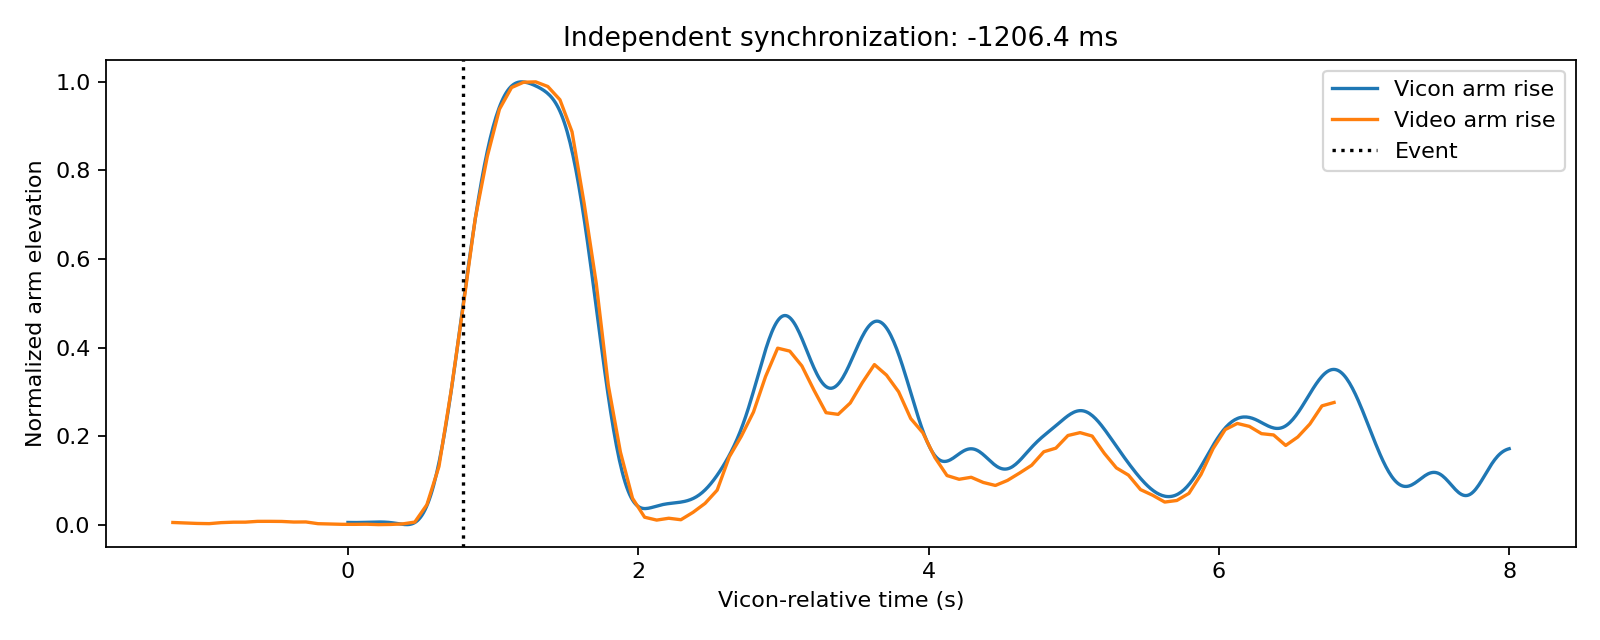

Candidate: cam0 — mediapipe


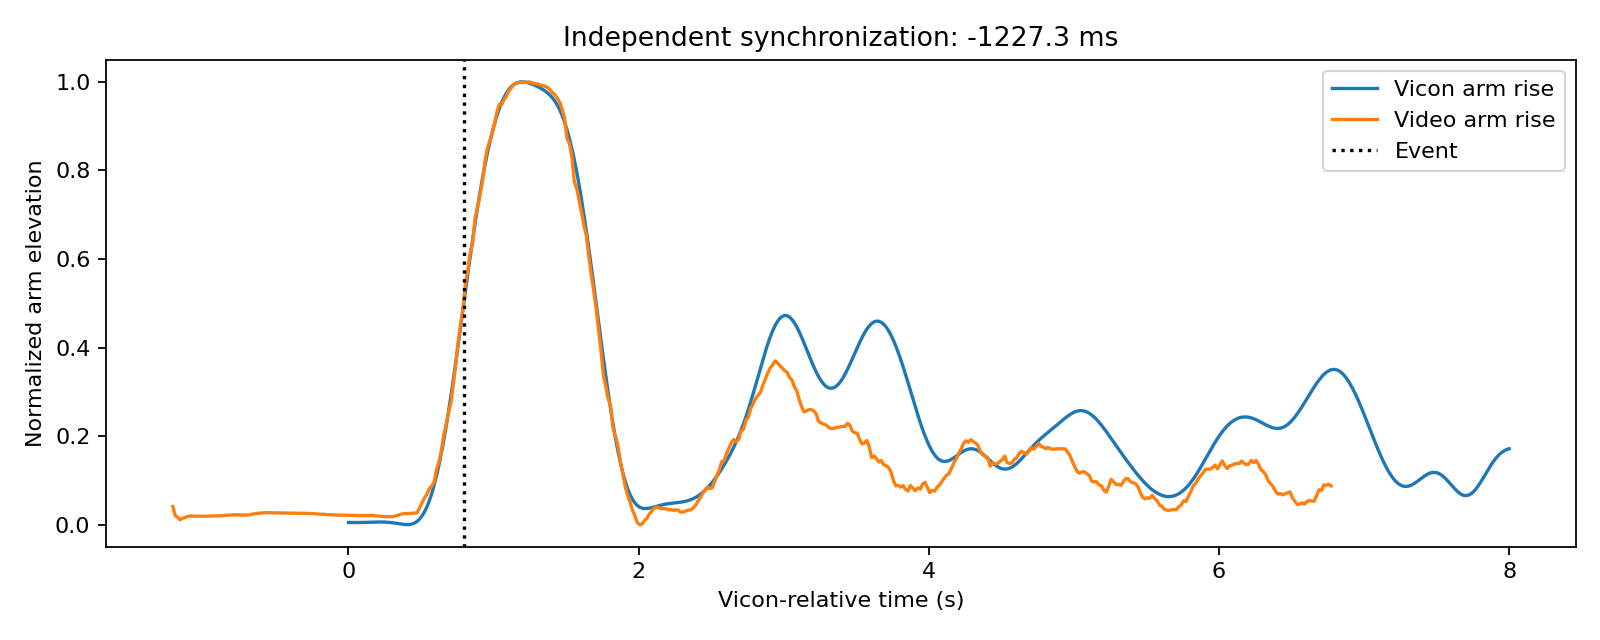

Candidate: cam1 — sam


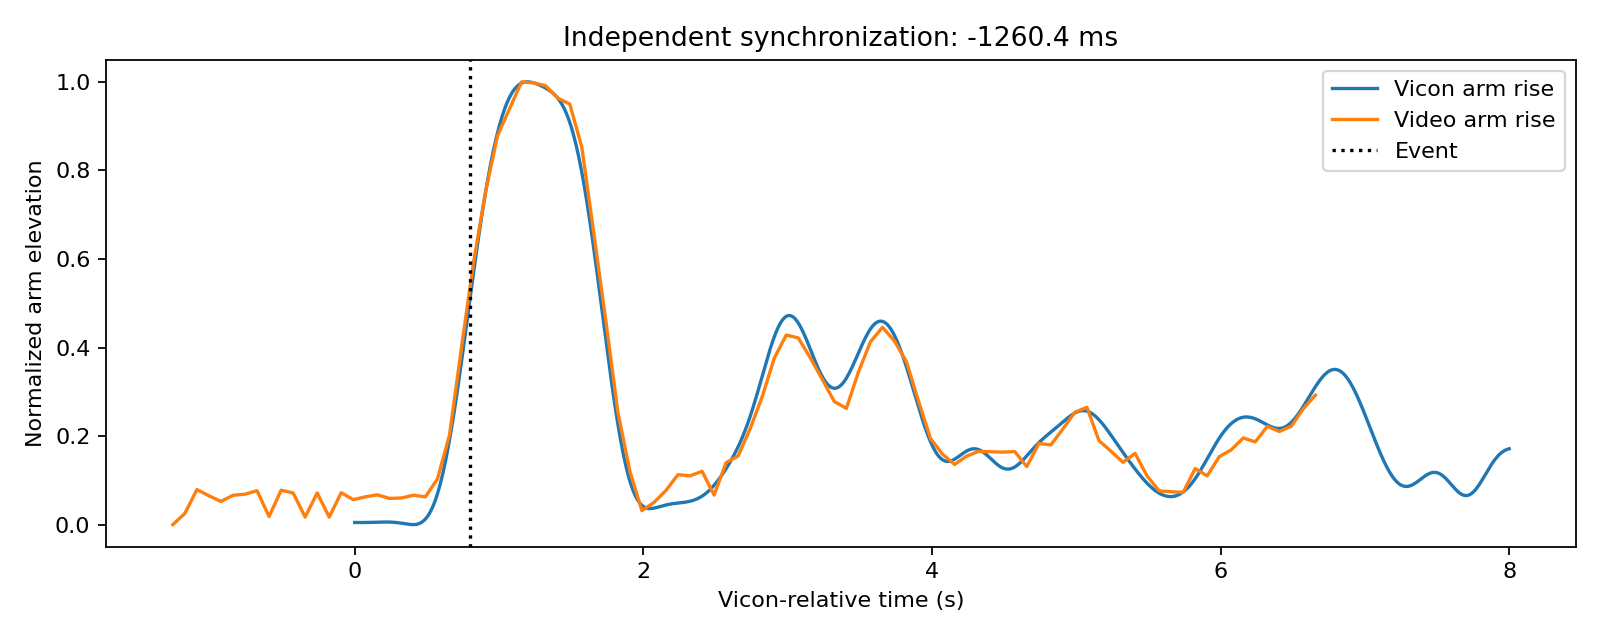

Candidate: cam1 — mediapipe


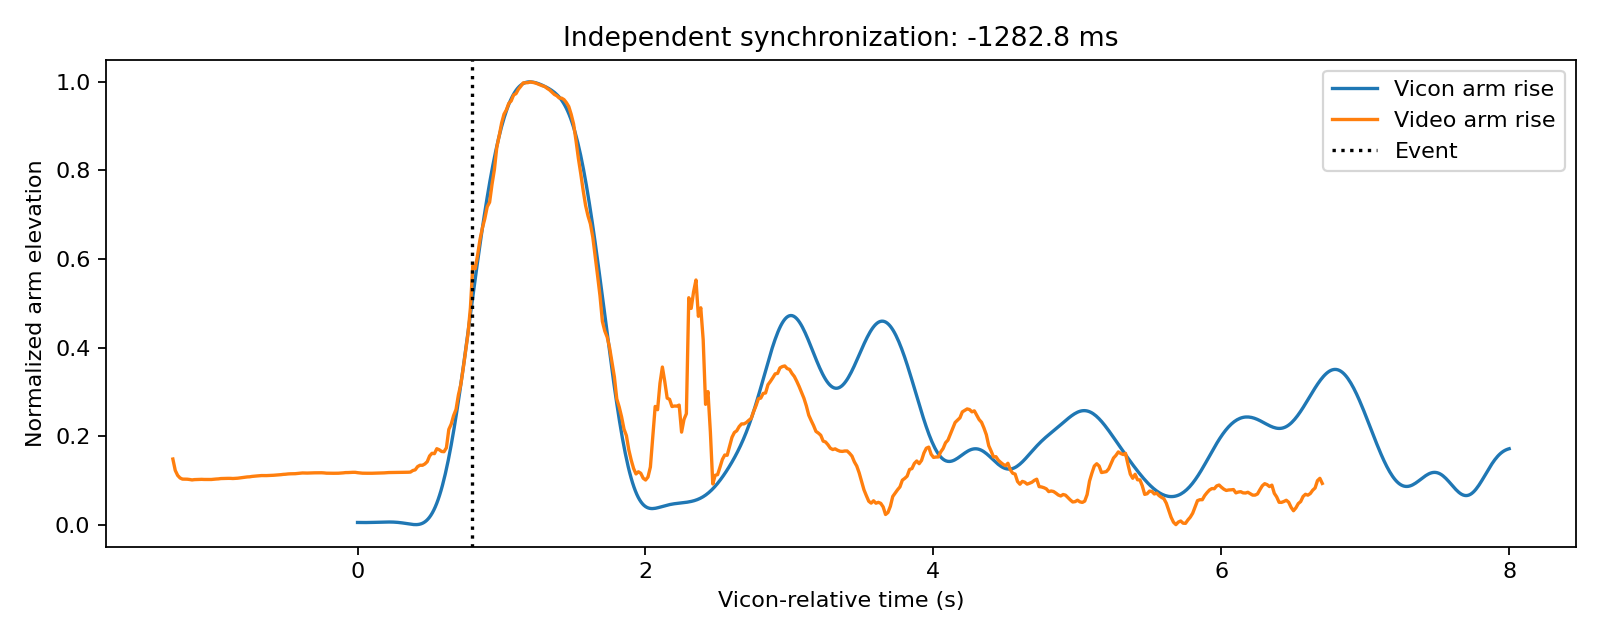

In [ ]:
import json
from dataclasses import asdict
from src.synchronization import SyncResult

records = []

for camera in CAMERAS:
    out_dir = RESULTS_DIR / SUBJECT / TRIAL / camera
    out_dir.mkdir(parents=True, exist_ok=True)
    for source, video_sync_path in SYNC_INPUTS[camera].items():
        row = dict(subject=SUBJECT, trial=TRIAL, camera=camera,
                   source=source, arm=SYNC_ARM, video_sync_file=video_sync_path.name)
        if not video_sync_path.is_file():
            records.append({**row, 'status':'missing_video_sync'})
            continue
        try:
            if SUBJECT.upper() == 'S1':
                    ve = S1_VIDEO_EVENT_MS.get(camera)
                    re = S1_VICON_EVENT_MS

                    if ve is None or re is None:
                        raise ValueError(
                            f'Set the S1 first-knee-bend timestamps for {camera}'
                        )

                    ve, re = float(ve), float(re)
                    if not np.isfinite([ve, re]).all() or min(ve, re) < 0:
                        raise ValueError('Event times must be finite, non-negative milliseconds')

                    result = SyncResult(
                        method='manual_first_knee_bend',
                        shift_ms=re - ve,
                        video_event_ms=ve,
                        vicon_event_ms=re,
                        video_prominence=None,
                        vicon_prominence=None,
                        status='review',
                        note='Manually identified first knee bend; verify a second shared event',
                    )

                    candidate = asdict(result)
                    candidate.update(sync_source=source, sync_event='first_knee_bend')
                    (out_dir / f'sync_candidate_{source}.json').write_text(
                        json.dumps(candidate, indent=2)
                    )

                    # Remove any old arm-raise plot for this candidate.
                    (out_dir / f'sync_candidate_{source}.png').unlink(missing_ok=True)

            else:
                    result = synchronize(
                        # Keep all your existing arguments here.
                    )

        records.append({**row, **vars(result)})

sync_summary = pd.DataFrame(records)
display(sync_summary)
summary_path = RESULTS_DIR / SUBJECT / TRIAL / 'sync_candidates_by_source.csv'
summary_path.parent.mkdir(parents=True, exist_ok=True)
sync_summary.to_csv(summary_path, index=False)
print('Saved candidate summary:', summary_path)

for _, row in sync_summary.iterrows():
    if row['status'] != 'review':
        print(row['camera'], row['source'], row['status'])
        continue
    plot_path = RESULTS_DIR / SUBJECT / TRIAL / row['camera'] / f"sync_candidate_{row['source']}.png"
    print(f"Candidate: {row['camera']} — {row['source']}")
    display(Image(filename=str(plot_path)))


## 4. Select the preferred synchronization source per camera

After visually inspecting both candidates and verifying that the detected event is the intended arm raise, update `SELECTED_SOURCE` in configuration (e.g. `{'cam0': 'mediapipe', 'cam1':'sam'}`). Run the cell below to copy its shift and metadata to the canonical `sync_candidate.json`. **This remains a review candidate**; separately check a second shared event for clock drift and mark approval in your final research QC workflow. If the event is absent from one source, leave the selection as `None` rather than forcing it.


In [30]:
import json

# Example after review: 
SELECTED_SOURCE = {'cam0': 'sam', 'cam1': 'sam'}

for camera, source in SELECTED_SOURCE.items():
    if source is None:
        print(f'{camera}: no source selected; existing canonical candidate unchanged')
        continue
    if source not in SYNC_SOURCES:
        raise ValueError(f'Unknown synchronization source for {camera}: {source}')

    directory = RESULTS_DIR / SUBJECT / TRIAL / camera
    chosen_path = directory / f'sync_candidate_{source}.json'
    if not chosen_path.is_file():
        print(f'{camera}: missing candidate {chosen_path.name}; not selected')
        continue
    with chosen_path.open() as f:
        chosen = json.load(f)
    if chosen.get('status') != 'review':
        print(f'{camera}: candidate has status {chosen.get("status")}; not selected')
        continue
    chosen['sync_source'] = source
    chosen['sync_arm'] = SYNC_ARM
    chosen['video_sync_file'] = SYNC_INPUTS[camera][source].name
    chosen['status'] = 'review'
    canonical = directory / 'sync_candidate.json'
    with canonical.open('w') as f:
        json.dump(chosen, f, indent=2)
    print(f'{camera}: selected {source} -> {canonical} (status=review)')


cam0: selected sam -> /Users/thomasjohnson/markerless/markerless_sam/results/S11/lunge_01/cam0/sync_candidate.json (status=review)
cam1: selected sam -> /Users/thomasjohnson/markerless/markerless_sam/results/S11/lunge_01/cam1/sync_candidate.json (status=review)
